# Paso 1: Carga y describe el dataset:

*   Importa los datos en un notebook.
*   Describe su estructura (número de registros, variables, tipos y significado).

In [1]:
import pandas as pd

# Ruta local del dataset
file_path = r'C:\IVAN\MNA\TC5061\semana-03\WA_Fn-UseC_-Telco-Customer-Churn.csv'

# Cargar dataset
df = pd.read_csv(file_path)

print("Dataset cargado correctamente.")

Dataset cargado correctamente.


In [2]:
print("Dimensiones del dataset:", df.shape)

print(f"Número de registros: {df.shape[0]:,}")
print(f"Número de variables: {df.shape[1]}")

Dimensiones del dataset: (7043, 21)
Número de registros: 7,043
Número de variables: 21


In [3]:
display(df.head())

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
print("Información general del dataset:")
df.info()

Información general del dataset:
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  70

In [5]:
print("Tipos de datos por variable:")
display(df.dtypes.to_frame(name='Tipo de dato'))

Tipos de datos por variable:


,Tipo de dato
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [6]:
display(df.describe(include='all').T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### **Descripción del dataset**

El conjunto de datos seleccionado es **Telco Customer Churn**, el cual contiene información de clientes de una empresa de telecomunicaciones. El dataset está compuesto por **7,043 registros y 21 variables**.

Las variables incluyen información demográfica de los clientes, características de los servicios contratados, antigüedad, tipo de contrato, método de pago y cargos asociados al servicio.

De acuerdo con la inspección inicial mediante `df.info()`, el conjunto de datos contiene 18 variables de tipo `object`, 2 variables de tipo `int64` y 1 variable de tipo `float64`. En esta primera revisión no se identificaron valores nulos, ya que las 21 variables presentan 7,043 valores no nulos.

La variable **`Churn`** representa si el cliente abandonó el servicio y será utilizada posteriormente como **variable objetivo (target)**. Por lo tanto, el problema de Machine Learning se plantea como un problema de **clasificación binaria**.

Durante la inspección también se identificó que la variable `TotalCharges`, aunque representa cargos monetarios acumulados, fue cargada como tipo `object`. Esta situación será revisada y tratada durante la etapa de preparación de los datos.



---



# Paso 2: Realiza un análisis exploratorio (EDA):

Genera estadísticas descriptivas y visualizaciones que te permitan entender la distribución de las variables y las relaciones entre ellas.

In [7]:
# Estadísticas descriptivas de las variables numéricas
df.describe().T

,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.0,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.0,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.5,70.35,89.85,118.75


In [8]:
# Estadísticas descriptivas de las variables categóricas
df.describe(include=['object']).T

C:\Users\IP65907\AppData\Local\Temp\ipykernel_25488\3738925051.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['object']).T


,count,unique,top,freq
customerID,7043,7043,7590-VHVEG,1
gender,7043,2,Male,3555
Partner,7043,2,No,3641
Dependents,7043,2,No,4933
PhoneService,7043,2,Yes,6361
MultipleLines,7043,3,No,3390
InternetService,7043,3,Fiber optic,3096
OnlineSecurity,7043,3,No,3498
OnlineBackup,7043,3,No,3088
DeviceProtection,7043,3,No,3095


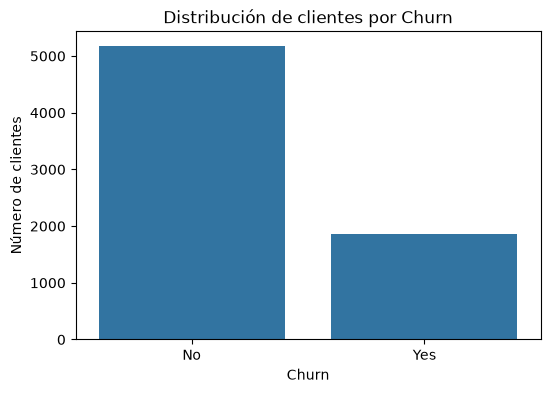

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6, 4))

sns.countplot(data=df, x='Churn')

plt.title('Distribución de clientes por Churn')
plt.xlabel('Churn')
plt.ylabel('Número de clientes')
plt.show()

In [10]:
churn_distribution = df['Churn'].value_counts()
churn_percentage = df['Churn'].value_counts(normalize=True) * 100

display(
    pd.DataFrame({
        'Frecuencia': churn_distribution,
        'Porcentaje': churn_percentage.round(2)
    })
)

,Frecuencia,Porcentaje
Churn,,
No,5174,73.46
Yes,1869,26.54


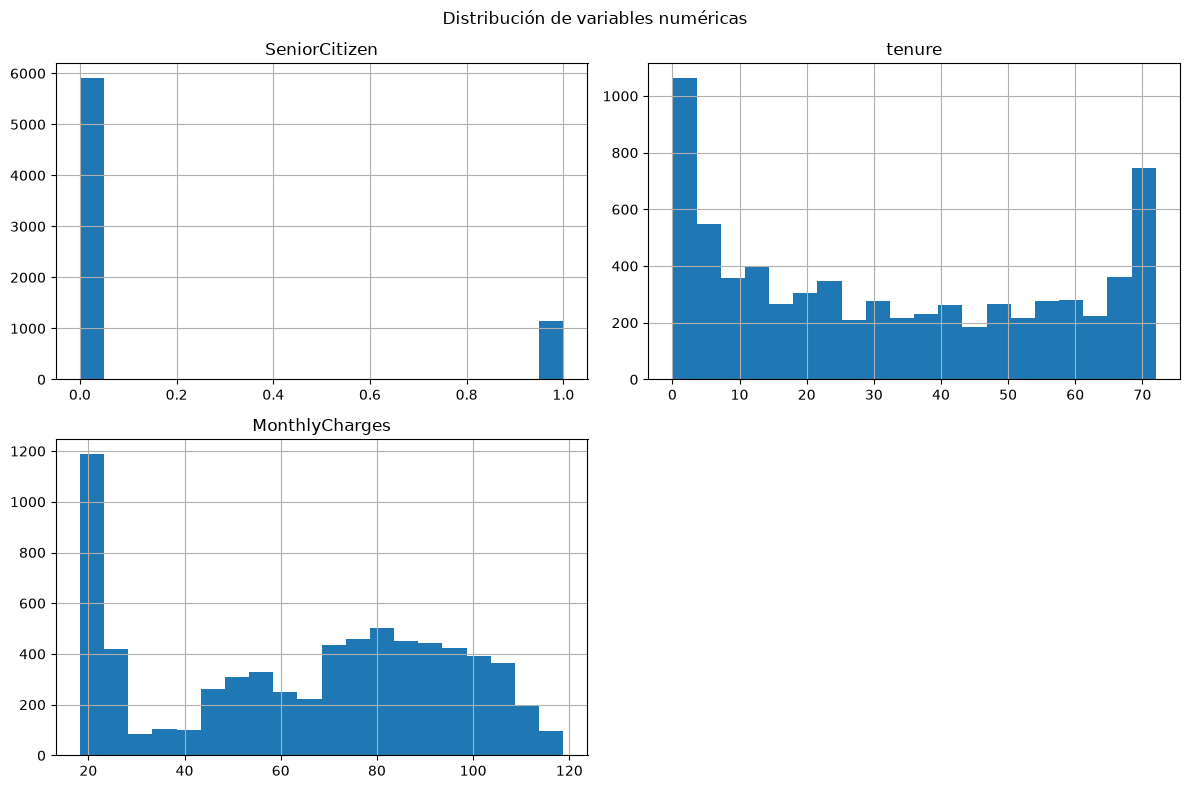

In [11]:
numeric_columns = ['SeniorCitizen', 'tenure', 'MonthlyCharges']

df[numeric_columns].hist(
    figsize=(12, 8),
    bins=20
)

plt.suptitle('Distribución de variables numéricas')
plt.tight_layout()
plt.show()

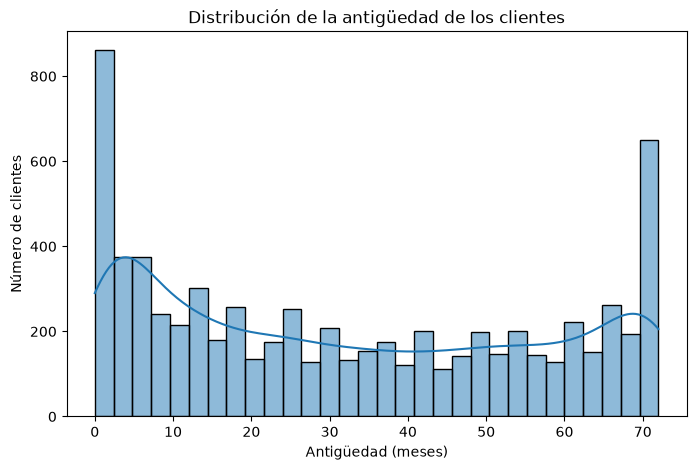

In [12]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='tenure', bins=30, kde=True)

plt.title('Distribución de la antigüedad de los clientes')
plt.xlabel('Antigüedad (meses)')
plt.ylabel('Número de clientes')
plt.show()

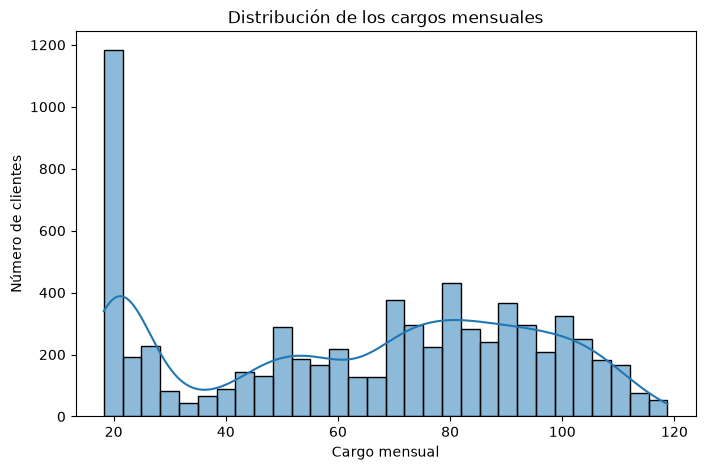

In [13]:
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x='MonthlyCharges', bins=30, kde=True)

plt.title('Distribución de los cargos mensuales')
plt.xlabel('Cargo mensual')
plt.ylabel('Número de clientes')
plt.show()

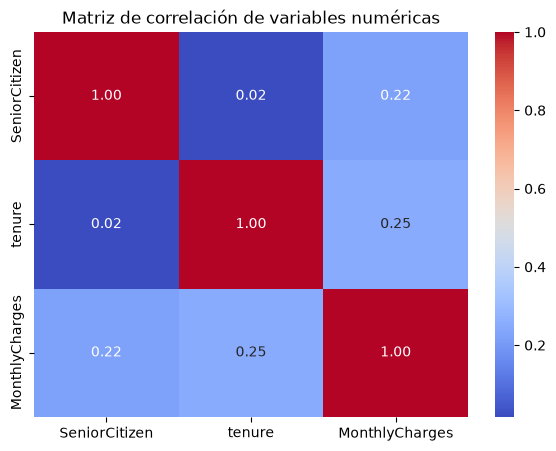

In [14]:
plt.figure(figsize=(7, 5))

correlation = df[numeric_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Matriz de correlación de variables numéricas')
plt.show()

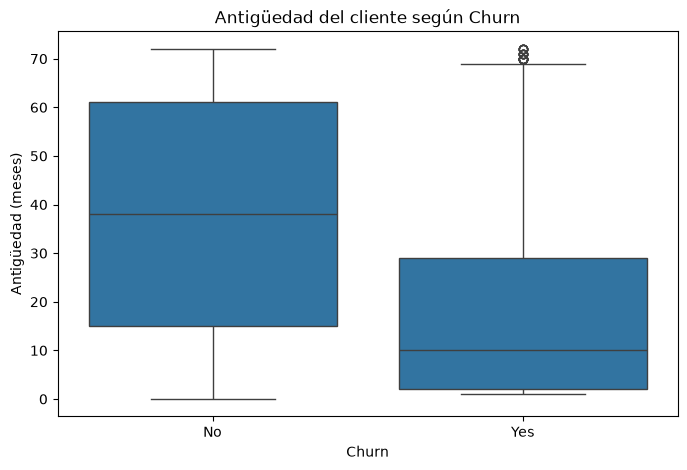

In [15]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='tenure'
)

plt.title('Antigüedad del cliente según Churn')
plt.xlabel('Churn')
plt.ylabel('Antigüedad (meses)')
plt.show()

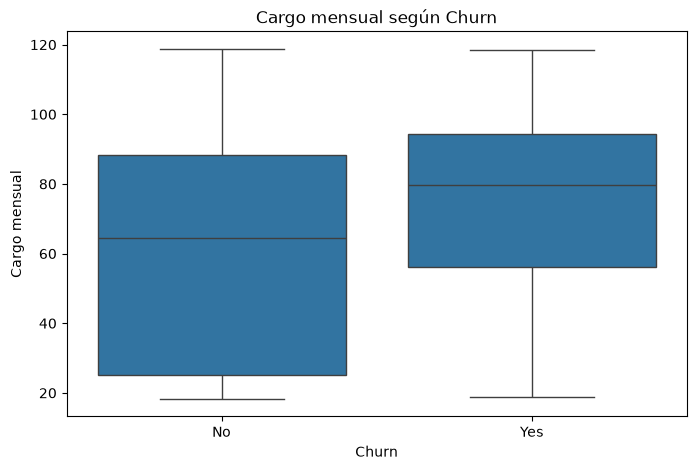

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x='Churn',
    y='MonthlyCharges'
)

plt.title('Cargo mensual según Churn')
plt.xlabel('Churn')
plt.ylabel('Cargo mensual')
plt.show()

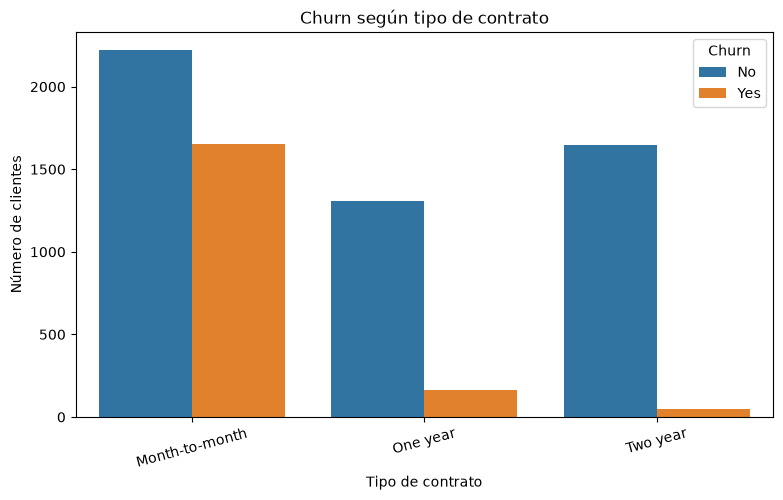

In [17]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='Contract',
    hue='Churn'
)

plt.title('Churn según tipo de contrato')
plt.xlabel('Tipo de contrato')
plt.ylabel('Número de clientes')
plt.xticks(rotation=15)
plt.legend(title='Churn')
plt.show()

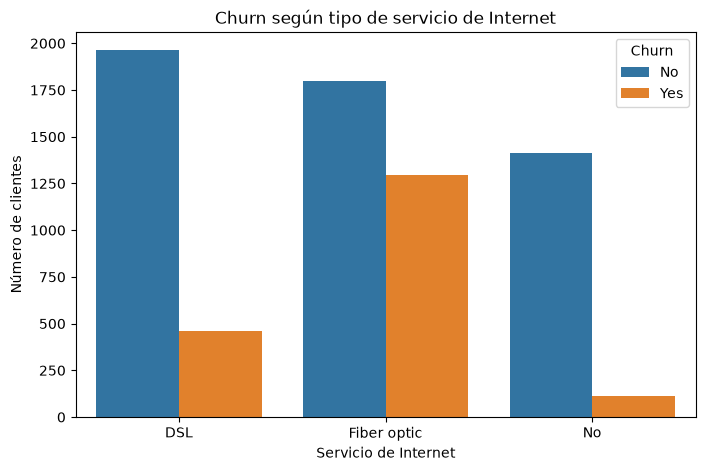

In [18]:
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='InternetService',
    hue='Churn'
)

plt.title('Churn según tipo de servicio de Internet')
plt.xlabel('Servicio de Internet')
plt.ylabel('Número de clientes')
plt.legend(title='Churn')
plt.show()

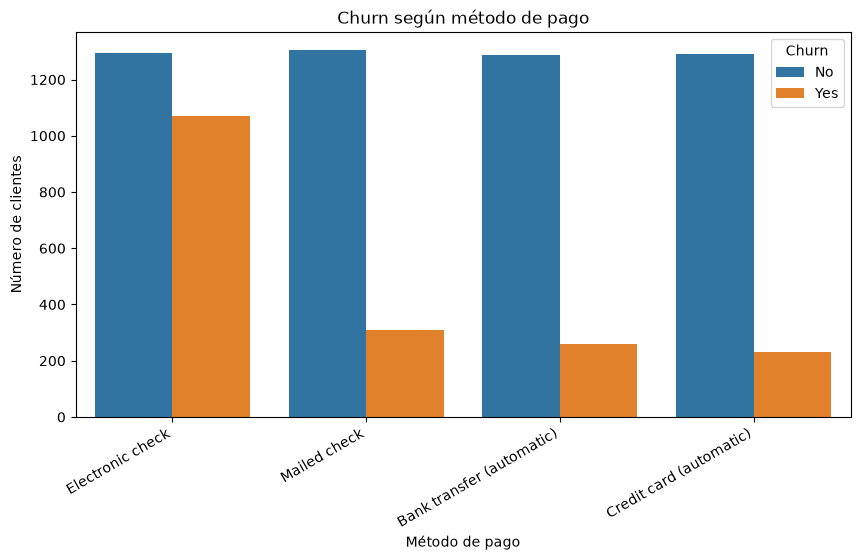

In [19]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='PaymentMethod',
    hue='Churn'
)

plt.title('Churn según método de pago')
plt.xlabel('Método de pago')
plt.ylabel('Número de clientes')
plt.xticks(rotation=30, ha='right')
plt.legend(title='Churn')
plt.show()

In [20]:
# Porcentaje de Churn por tipo de contrato
contract_churn = pd.crosstab(
    df['Contract'],
    df['Churn'],
    normalize='index'
) * 100

display(contract_churn.round(2))

Churn,No,Yes
Contract,,
Month-to-month,57.29,42.71
One year,88.73,11.27
Two year,97.17,2.83


In [21]:
# Porcentaje de Churn por tipo de servicio de Internet
internet_churn = pd.crosstab(
    df['InternetService'],
    df['Churn'],
    normalize='index'
) * 100

display(internet_churn.round(2))

Churn,No,Yes
InternetService,,
DSL,81.04,18.96
Fiber optic,58.11,41.89
No,92.60,7.40


In [22]:
# Porcentaje de Churn por método de pago
payment_churn = pd.crosstab(
    df['PaymentMethod'],
    df['Churn'],
    normalize='index'
) * 100

display(payment_churn.round(2))

Churn,No,Yes
PaymentMethod,,
Bank transfer (automatic),83.29,16.71
Credit card (automatic),84.76,15.24
Electronic check,54.71,45.29
Mailed check,80.89,19.11


In [23]:
tenure_churn = df.groupby('Churn')['tenure'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

display(tenure_churn.round(2))

,count,mean,median,std,min,max
Churn,,,,,,
No,5174,37.57,38.0,24.11,0,72
Yes,1869,17.98,10.0,19.53,1,72


In [24]:
monthly_charges_churn = df.groupby('Churn')['MonthlyCharges'].agg(
    ['count', 'mean', 'median', 'std', 'min', 'max']
)

display(monthly_charges_churn.round(2))

,count,mean,median,std,min,max
Churn,,,,,,
No,5174,61.27,64.43,31.09,18.25,118.75
Yes,1869,74.44,79.65,24.67,18.85,118.35


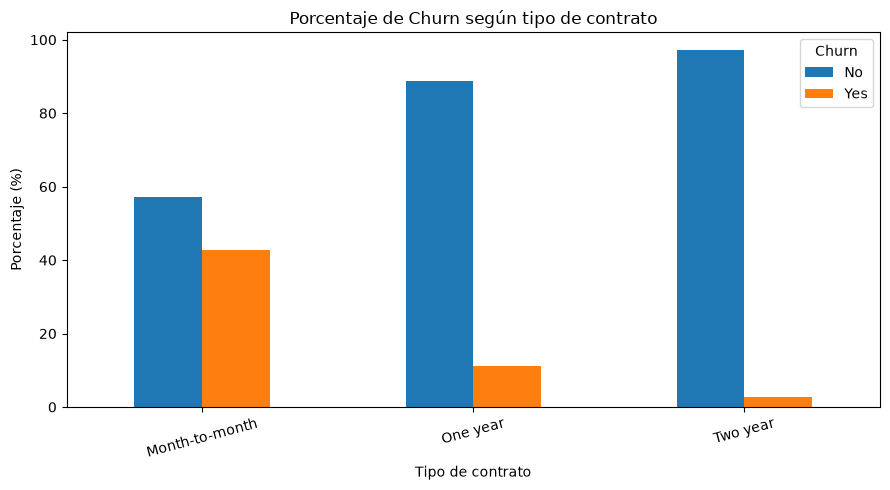

In [25]:
contract_churn.plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Porcentaje de Churn según tipo de contrato')
plt.xlabel('Tipo de contrato')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=15)
plt.legend(title='Churn')
plt.tight_layout()
plt.show()

## **Interpretación del análisis exploratorio**

El análisis exploratorio permitió identificar patrones relevantes en el comportamiento de los clientes. La variable `Churn` presenta un desbalance moderado: **26.54 %** de los clientes abandonaron el servicio, mientras que **73.46 %** permanecieron.

Se observa una relación importante entre la **antigüedad del cliente (`tenure`) y el abandono**. Los clientes que permanecieron tienen una antigüedad promedio de **37.57 meses**, mientras que los que abandonaron presentan un promedio de **17.98 meses**. Además, los clientes que abandonaron tienen cargos mensuales promedio mayores (**74.44**) que quienes permanecieron (**61.27**).

Las variables categóricas también muestran diferencias relevantes. El porcentaje de abandono es mayor entre los clientes con contrato **Month-to-month (42.71 %)**, servicio de Internet **Fiber optic (41.89 %)** y método de pago **Electronic check (45.29 %)**. En contraste, los contratos de uno y dos años presentan tasas de abandono considerablemente menores.

En conjunto, el EDA identifica a **`tenure`, `MonthlyCharges`, `Contract`, `InternetService` y `PaymentMethod`** como variables potencialmente relevantes para predecir el abandono. Estos hallazgos servirán como base para la siguiente etapa de **preparación y modelado de los datos**.




---



# Paso 3: Limpia los datos:

*   Identifica y trata valores faltantes, duplicados, outliers y tipos incorrectos.
*   Documenta cada decisión que tomes.


In [26]:
# Revisar valores nulos
missing_values = df.isnull().sum()

display(
    missing_values[missing_values > 0]
)

Series([], dtype: int64)

In [27]:
# Revisar cadenas vacías o espacios en variables de tipo object
for col in df.select_dtypes(include='object').columns:
    empty_values = df[col].astype(str).str.strip().eq('').sum()

    if empty_values > 0:
        print(f"{col}: {empty_values} valores vacíos")

TotalCharges: 11 valores vacíos


C:\Users\IP65907\AppData\Local\Temp\ipykernel_25488\1113169448.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [28]:
# Convertir TotalCharges a numérico
df['TotalCharges'] = pd.to_numeric(
    df['TotalCharges'],
    errors='coerce'
)

# Verificar los valores faltantes generados
print("Valores faltantes en TotalCharges:",
      df['TotalCharges'].isnull().sum())

Valores faltantes en TotalCharges: 11


In [29]:
display(
    df[df['TotalCharges'].isnull()]
)

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,3115-CZMZD,Male,0,No,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,5709-LVOEQ,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,...,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,4367-NUYAO,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,1371-DWPAZ,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,...,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,7644-OMVMY,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,3213-VVOLG,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,2520-SGTTA,Female,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,2923-ARZLG,Male,0,Yes,Yes,0,Yes,No,No,No internet service,...,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,4075-WKNIU,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,...,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [30]:
df.loc[df['TotalCharges'].isnull(), 'TotalCharges'] = 0

In [31]:
print("Valores faltantes después del tratamiento:")
display(df.isnull().sum()[df.isnull().sum() > 0])

Valores faltantes después del tratamiento:


Series([], dtype: int64)

In [32]:
# Número de registros duplicados
duplicates = df.duplicated().sum()

print(f"Número de registros duplicados: {duplicates}")

Número de registros duplicados: 0


In [33]:
print("IDs de clientes duplicados:",
      df['customerID'].duplicated().sum())

IDs de clientes duplicados: 0


In [34]:
# Identificación de outliers mediante IQR
# Se aplica únicamente a variables numéricas continuas

numeric_continuous = [
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

for col in numeric_continuous:

    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"{col}:")
    print(f"  Límite inferior: {lower_bound:.2f}")
    print(f"  Límite superior: {upper_bound:.2f}")
    print(f"  Número de outliers: {len(outliers)}")
    print()

tenure:
  Límite inferior: -60.00
  Límite superior: 124.00
  Número de outliers: 0

MonthlyCharges:
  Límite inferior: -46.02
  Límite superior: 171.38
  Número de outliers: 0

TotalCharges:
  Límite inferior: -4683.52
  Límite superior: 8868.67
  Número de outliers: 0



In [35]:
print("Tipos de datos después de la limpieza:")
display(df.dtypes.to_frame(name='Tipo de dato'))

Tipos de datos después de la limpieza:


,Tipo de dato
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


In [36]:
print("Variables numéricas:")
display(df[numeric_columns].dtypes.to_frame(name='Tipo de dato'))

Variables numéricas:


,Tipo de dato
SeniorCitizen,int64
tenure,int64
MonthlyCharges,float64


In [37]:
print("Dimensiones finales:", df.shape)

print("\nValores faltantes:")
print(df.isnull().sum().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nTipos de datos:")
display(df.dtypes.to_frame(name='Tipo de dato'))

Dimensiones finales: (7043, 21)

Valores faltantes:
0

Registros duplicados:
0

Tipos de datos:


,Tipo de dato
customerID,str
gender,str
SeniorCitizen,int64
Partner,str
Dependents,str
tenure,int64
PhoneService,str
MultipleLines,str
InternetService,str
OnlineSecurity,str


## Interpretación de la limpieza de datos

La revisión permitió identificar **11 cadenas vacías en `TotalCharges`**. Esta variable se convirtió de texto a formato numérico y las cadenas que no pudieron convertirse fueron identificadas como valores faltantes. Al comprobar los registros afectados, se observó que correspondían a clientes con `tenure = 0`, por lo que se asignó `TotalCharges = 0`.

No se encontraron **registros duplicados ni clientes con `customerID` repetido**. Para la detección de *outliers* se utilizó el método IQR en las variables numéricas continuas (`tenure`, `MonthlyCharges` y `TotalCharges`), sin encontrar valores extremos que justificaran su eliminación. `SeniorCitizen` no se consideró para este análisis porque es una variable binaria.

Después de la limpieza, el dataset conserva sus **7,043 registros y 21 variables**, sin valores faltantes ni duplicados y con los tipos de datos corregidos, quedando preparado para la siguiente etapa de preprocesamiento y modelado.




---



# Paso 4: Entrena un modelo base:

*  Selecciona un modelo sencillo (baseline) apropiado para el problema.
*  Divide los datos en entrenamiento y prueba, y entrénalo.





In [38]:
# Variable objetivo
y = df['Churn'].map({'No': 0, 'Yes': 1})

# Variables predictoras
X = df.drop(columns=['Churn', 'customerID'])

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

display(X.head())
display(y.head())

Dimensiones de X: (7043, 19)
Dimensiones de y: (7043,)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65


0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64

In [39]:
# Variables numéricas
numeric_features = [
    'SeniorCitizen',
    'tenure',
    'MonthlyCharges',
    'TotalCharges'
]

# Variables categóricas
categorical_features = [
    col for col in X.columns
    if col not in numeric_features
]

print("Variables numéricas:")
print(numeric_features)

print("\nVariables categóricas:")
print(categorical_features)

Variables numéricas:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Variables categóricas:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nDistribución de Churn en entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución de Churn en prueba:")
print(y_test.value_counts(normalize=True))

Datos de entrenamiento: (5634, 19)
Datos de prueba: (1409, 19)

Distribución de Churn en entrenamiento:
Churn
0    0.734647
1    0.265353
Name: proportion, dtype: float64

Distribución de Churn en prueba:
Churn
0    0.734564
1    0.265436
Name: proportion, dtype: float64


In [41]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            StandardScaler(),
            numeric_features
        ),
        (
            'cat',
            OneHotEncoder(handle_unknown='ignore'),
            categorical_features
        )
    ]
)

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

baseline_model = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]
)

In [43]:
baseline_model.fit(X_train, y_train)

print("Modelo baseline entrenado correctamente.")

Modelo baseline entrenado correctamente.


In [44]:
y_pred = baseline_model.predict(X_test)

print("Predicciones generadas correctamente.")
print("Número de predicciones:", len(y_pred))

Predicciones generadas correctamente.
Número de predicciones: 1409


In [45]:
y_prob = baseline_model.predict_proba(X_test)[:, 1]

display(y_prob[:10])

array([0.04591993, 0.68371345, 0.05893985, 0.40183529, 0.02142426,
       0.60297803, 0.44762898, 0.13033554, 0.00280355, 0.39473874])

## Interpretación del modelo base

Se seleccionó **Regresión Logística** como modelo baseline debido a que el problema corresponde a una clasificación binaria de la variable `Churn`. El dataset se dividió en **5,634 registros para entrenamiento (80 %) y 1,409 para prueba (20 %)**, utilizando estratificación para mantener la proporción de clientes que abandonaron y permanecieron en ambos conjuntos.

Se excluyó `customerID` por ser un identificador sin valor predictivo. Las variables categóricas fueron transformadas mediante **One-Hot Encoding** y las variables numéricas fueron estandarizadas mediante `StandardScaler`, integrando ambos procesos en un `Pipeline` para evitar fuga de información.

El modelo fue entrenado correctamente y generó **1,409 predicciones** sobre el conjunto de prueba. También se obtuvieron las probabilidades de pertenencia a la clase `Churn = 1`, que serán utilizadas para evaluar el desempeño del modelo en la siguiente etapa.




---

# Paso 5: Evalúa el modelo:
*   Calcula al menos una métrica de desempeño coherente con el tipo de problema.
*   Interpreta el resultado de manera detallada.





In [46]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calcular métricas
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Métricas del modelo baseline:")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-Score : {f1:.4f}")
print(f"ROC-AUC  : {roc_auc:.4f}")

Métricas del modelo baseline:
Accuracy : 0.8055
Precision: 0.6572
Recall   : 0.5588
F1-Score : 0.6040
ROC-AUC  : 0.8421


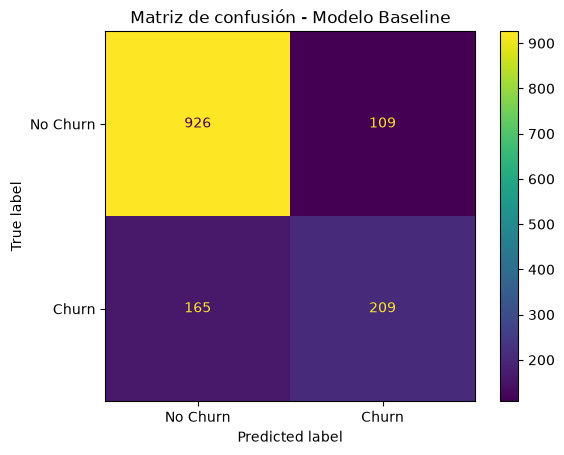

In [47]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No Churn', 'Churn']
)

disp.plot()
plt.title('Matriz de confusión - Modelo Baseline')
plt.show()

In [48]:
from sklearn.metrics import classification_report

print("Reporte de clasificación:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=['No Churn', 'Churn']
    )
)

Reporte de clasificación:
              precision    recall  f1-score   support

    No Churn       0.85      0.89      0.87      1035
       Churn       0.66      0.56      0.60       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



## Interpretación de la evaluación del modelo

El modelo de Regresión Logística obtuvo un **Accuracy de 80.55 %** y un **ROC-AUC de 84.21 %**, lo que indica un desempeño general favorable y una buena capacidad para distinguir entre clientes que abandonan y permanecen.

Para la clase `Churn`, el modelo alcanzó una **Precision de 65.72 %**, un **Recall de 55.88 %** y un **F1-Score de 60.40 %**. El Recall indica que el modelo identifica correctamente aproximadamente el **56 % de los clientes que realmente abandonan**, mientras que el resto no es detectado.

La matriz de confusión muestra **209 verdaderos positivos y 165 falsos negativos**, por lo que la principal oportunidad de mejora es incrementar la capacidad del modelo para identificar clientes con riesgo de abandono.

En conclusión, la Regresión Logística proporciona un **baseline razonable**, pero su desempeño en la detección de `Churn` puede mejorarse mediante modelos o estrategias de preprocesamiento posteriores.


# Paso 6: Registra el experimento en MLFlow:
* Usa MLFlow Tracking para registrar parámetros y métricas.
* Solo si aplica, registra los artefactos del modelo base.

In [49]:
import mlflow
import mlflow.sklearn

# Configurar el servidor de MLflow
mlflow.set_tracking_uri("http://127.0.0.1:5000")

# Crear o seleccionar el experimento
mlflow.set_experiment("Telco_Customer_Churn_Baseline")

print("MLflow Tracking configurado correctamente.")

MLflow Tracking configurado correctamente.


In [50]:
import mlflow
import mlflow.sklearn

# Parámetros del experimento
params = {
    "model": "LogisticRegression",
    "max_iter": 1000,
    "random_state": 42,
    "test_size": 0.20,
    "encoding": "OneHotEncoder",
    "scaling": "StandardScaler"
}

# Métricas obtenidas en el Paso 5
metrics = {
    "accuracy": accuracy,
    "precision": precision,
    "recall": recall,
    "f1_score": f1,
    "roc_auc": roc_auc
}

# Registrar experimento en MLflow
with mlflow.start_run(run_name="LogisticRegression_Baseline"):

    # Registrar parámetros
    mlflow.log_params(params)

    # Registrar métricas
    mlflow.log_metrics(metrics)

    # Registrar el modelo base
    mlflow.sklearn.log_model(
        sk_model=baseline_model,
        name="logistic_regression_baseline",
        input_example=X_test.iloc[[0]]
    )

    print("Experimento registrado correctamente en MLflow.")
    print("Run ID:", mlflow.active_run().info.run_id)

C:\Python314\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
C:\Python314\Lib\site-packages\mlflow\types\utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be enco

Experimento registrado correctamente en MLflow.
Run ID: 637ecdcd00f445b49b4b02e661a12da6
🏃 View run LogisticRegression_Baseline at: http://127.0.0.1:5000/#/experiments/3/runs/637ecdcd00f445b49b4b02e661a12da6
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3


# Paso 7: Redacta una reflexión:

* Al final del notebook, explica brevemente qué mejorarías en este flujo aplicando prácticas de MLOps y por qué.
* ¿Cómo se ven reflejados estos aprendizajes dentro de tu área profesional?
* 150 palabras o más de extensión. 

## Reflexión

El flujo desarrollado permitió comprender de manera práctica las principales etapas de un proyecto de Machine Learning: exploración y limpieza de datos, preparación de variables, entrenamiento de un modelo base, evaluación y registro del experimento. Aplicando prácticas de MLOps, mejoraría este flujo incorporando una estrategia formal de **control de versiones** para el código, los datos y las configuraciones del experimento, además de automatizar el entrenamiento y la evaluación mediante un pipeline de **CI/CD**. También incorporaría validaciones automáticas de calidad de datos, seguimiento de cambios en los datasets y experimentos, y monitoreo del desempeño del modelo una vez desplegado. Herramientas como MLflow permitirían mantener la trazabilidad de parámetros, métricas, modelos y artefactos, facilitando la reproducibilidad y comparación entre experimentos.

Estos aprendizajes tienen una relación directa con mi área profesional en desarrollo de software dentro del sector financiero, donde la automatización, la trazabilidad, la seguridad y la calidad son fundamentales. Conceptos como CI/CD, control de versiones, pruebas automatizadas, observabilidad y gestión de artefactos ya forman parte de las prácticas de ingeniería de software. La incorporación de MLOps extiende estas prácticas al ciclo de vida de los modelos de Machine Learning, permitiendo integrar modelos de IA de manera controlada, reproducible y escalable dentro de los procesos tecnológicos de una organización.
